# Figure 1 descriptive prototype

Builds the descriptive Figure 1 concept from the final Andes-included sequence-level label set. The figure has no title, uses Helvetica Neue fallbacks, and keeps the pastel palette used in the manuscript-facing figures.

In [1]:
from pathlib import Path
import importlib.util

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

NOTEBOOK_DIR = Path.cwd().resolve()
REPO_ROOT = next(path for path in [NOTEBOOK_DIR, *NOTEBOOK_DIR.parents] if (path / "Scripts").exists() or (path / "model_test").exists())

OUT_DIR = REPO_ROOT / "Notebooks" / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Reuse the existing tree/path-state helper used for the supplemental validation figure.
helper_path = REPO_ROOT / "Scripts" / "ReassortmentInference" / "build_reassortment_validation_outputs.py"
if not helper_path.exists():
    helper_path = REPO_ROOT / "model_test" / "scripts" / "build_reassortment_validation_outputs.py"
spec = importlib.util.spec_from_file_location("reassortment_validation", helper_path)
validation = importlib.util.module_from_spec(spec)
spec.loader.exec_module(validation)


In [2]:
FINAL_LABEL_PATHS = [
    REPO_ROOT / "model_test" / "runs" / "model_sequence" / "datasets" / "sequence_true_labels_pathoplexus_andes_only.tsv",
    REPO_ROOT / "model_test" / "runs" / "multi_species_backfill_true_reassortment_full" / "sequence_true_labels.tsv",
    REPO_ROOT / "model_test" / "runs" / "snv_backfill_true_reassortment" / "sequence_true_labels.tsv",
]

SPECIES_LABELS = {
    "orthohantavirus_andesense": "Andes",
    "orthohantavirus_dobravaense": "Dobrava-Belgrade",
    "orthohantavirus_hantanense": "Hantaan",
    "orthohantavirus_puumalaense": "Puumala",
    "orthohantavirus_seoulense": "Seoul",
    "orthohantavirus_sinnombreense": "Sin Nombre",
    "orthohantavirus_tulaense": "Tula",
}

SPECIES_ORDER = [
    "Andes",
    "Hantaan",
    "Tula",
    "Puumala",
    "Seoul",
    "Sin Nombre",
    "Dobrava-Belgrade",
]

PASTEL_SPECIES = {
    "Andes": "#D8C7F2",
    "Hantaan": "#BCD7F0",
    "Tula": "#C6E2DD",
    "Puumala": "#D7EBC4",
    "Seoul": "#F5D2AC",
    "Sin Nombre": "#F5C2CD",
    "Dobrava-Belgrade": "#E3C1D4",
}

COLORS = {
    "ink": "#303030",
    "muted": "#6F6F6F",
    "grid": "#E5E5E5",
    "records": "#BED7EF",
    "complete": "#CDE6C8",
    "tree_ready": "#F6E4A8",
    "reassortant": "#E99AA7",
    "non_reassortant": "#E7E7E7",
    "black": "#111111",
}
PATH_STATE_COLORS = ["#1b9e77", "#d95f02", "#7570b3"]

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelsize": 9.5,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 9,
    "legend.fontsize": 8.3,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


In [3]:
labels = pd.concat([pd.read_csv(path, sep="\t") for path in FINAL_LABEL_PATHS], ignore_index=True)
labels["species_label"] = labels["species"].map(SPECIES_LABELS)
labels["min_distance_to_reassort_node"] = pd.to_numeric(
    labels["min_distance_to_reassort_node"], errors="coerce"
)

species_summary = (
    labels.groupby("species_label", as_index=False)
    .agg(reassortants=("is_reassortant", "sum"), total=("is_reassortant", "size"))
)
species_summary["rate"] = species_summary["reassortants"] / species_summary["total"]
species_summary["species_label"] = pd.Categorical(
    species_summary["species_label"], categories=SPECIES_ORDER, ordered=True
)
species_summary = species_summary.sort_values("species_label")

final_reassortants = int(labels["is_reassortant"].sum())
final_non_reassortants = int(len(labels) - final_reassortants)

tula = labels[labels["species"].eq("orthohantavirus_tulaense")].copy()
tula_reassortants = int(tula["is_reassortant"].sum())
tula_total = int(len(tula))
tula_reassortant_median_distance = tula.loc[
    tula["is_reassortant"].eq(1), "min_distance_to_reassort_node"
].median()
tula_non_reassortant_finite_median_distance = tula.loc[
    tula["is_reassortant"].eq(0), "min_distance_to_reassort_node"
].median()

species_summary


,species_label,reassortants,total,rate
0,Andes,0,61,0.000000
2,Hantaan,29,199,0.145729
6,Tula,27,71,0.380282
3,Puumala,28,69,0.405797
4,Seoul,47,101,0.465347
5,Sin Nombre,20,34,0.588235
1,Dobrava-Belgrade,12,18,0.666667


In [4]:
def add_flow_panel(ax):
    ax.set_axis_off()
    ax.text(0, 1.02, "a)", transform=ax.transAxes, fontsize=13, fontweight="bold", color=COLORS["ink"])

    steps = [
        ("2,131", "Harmonized\nrecords", COLORS["records"], 0.02),
        ("638", "Complete S/M/L\nisolates", COLORS["complete"], 0.37),
        ("553", "Final sequence\ndataset", COLORS["tree_ready"], 0.72),
    ]
    for idx, (number, label, color, x_pos) in enumerate(steps):
        ax.add_patch(FancyBboxPatch(
            (x_pos, 0.61),
            0.255,
            0.24,
            boxstyle="round,pad=0.012,rounding_size=0.024",
            facecolor=color,
            edgecolor="#8E8E8E",
            lw=0.9,
            transform=ax.transAxes,
        ))
        ax.text(
            x_pos + 0.127,
            0.795,
            number,
            ha="center",
            va="center",
            fontsize=14,
            fontweight="bold",
            color=COLORS["ink"],
            transform=ax.transAxes,
        )
        ax.text(
            x_pos + 0.127,
            0.67,
            label,
            ha="center",
            va="center",
            fontsize=8.7,
            color=COLORS["ink"],
            linespacing=1,
            transform=ax.transAxes,
        )

    ax.text(
        0.07,
        0.405,
        "Reassortment inference with Espalier",
        ha="left",
        va="center",
        fontsize=8.8,
        color=COLORS["muted"],
        transform=ax.transAxes,
        linespacing=1.08,
    )
    # ax.plot([0.85, 0.85], [0.605, 0.445], color="#858585", lw=1, transform=ax.transAxes)
    # ax.plot([0.52, 0.99], [0.445, 0.445], color="#858585", lw=1, transform=ax.transAxes)

    outputs = [
        (0.37, f"{final_reassortants:,}", "Reassortants", COLORS["reassortant"]),
        (0.72, f"{final_non_reassortants:,}", "Non-reassortants", COLORS["non_reassortant"]),
    ]
    for x_pos, number, label, color in outputs:
        ax.add_patch(FancyBboxPatch(
            (x_pos, 0.105),
            0.26,
            0.205,
            boxstyle="round,pad=0.012,rounding_size=0.024",
            facecolor=color,
            edgecolor="#8E8E8E",
            lw=0.9,
            transform=ax.transAxes,
        ))
        ax.text(
            x_pos + 0.13,
            0.225,
            number,
            ha="center",
            va="center",
            fontsize=14,
            fontweight="bold",
            color=COLORS["ink"],
            transform=ax.transAxes,
        )
        ax.text(
            x_pos + 0.13,
            0.15,
            label,
            ha="center",
            va="center",
            fontsize=8.1,
            color=COLORS["ink"],
            linespacing=0.98,
            transform=ax.transAxes,
        )


def add_species_rate_panel(ax):
    ax.text(-0.075, 1.01, "b)", transform=ax.transAxes, fontsize=13, fontweight="bold", color=COLORS["ink"])
    display = species_summary.iloc[::-1].reset_index(drop=True)
    ypos = np.arange(len(display))

    ax.barh(ypos, 100, color=COLORS["non_reassortant"], edgecolor="white", height=0.62)
    ax.barh(
        ypos,
        display["rate"] * 100,
        color=[PASTEL_SPECIES[str(species)] for species in display["species_label"]],
        edgecolor="white",
        height=0.62,
    )
    for y_val, row in zip(ypos, display.itertuples(index=False)):
        ax.text(
            max(row.rate * 100 + 2, 3),
            y_val,
            f"{row.rate:.0%} ({int(row.reassortants)}/{int(row.total)})",
            ha="left",
            va="center",
            fontsize=8.8,
            color=COLORS["ink"],
        )

    ax.set_yticks(ypos)
    ax.set_yticklabels(display["species_label"].astype(str))
    ax.set_xlabel("Reassortant descendants (%)")
    ax.set_xlim(0, 100)
    ax.grid(axis="x", color=COLORS["grid"], lw=0.8)
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.legend(
        handles=[
            Line2D(
                [0],
                [0],
                marker="s",
                color="none",
                markerfacecolor=COLORS["non_reassortant"],
                markeredgecolor="#B8B8B8",
                markersize=8,
                label="Non-reassortant",
            ),
            Line2D(
                [0],
                [0],
                marker="s",
                color="none",
                markerfacecolor=COLORS["reassortant"],
                markeredgecolor="#B8B8B8",
                markersize=8,
                label="Reassortant",
            ),
        ],
        frameon=False,
        loc="upper right",
        bbox_to_anchor=(1, 1.055),
        ncol=2,
        columnspacing=1.2,
        handletextpad=0.4,
    )


def add_tula_tree_panel(ax):
    ax.set_axis_off()
    ax.text(0, 1.025, "c)", transform=ax.transAxes, fontsize=13, fontweight="bold", color=COLORS["ink"])

    tree_ax = inset_axes(
        ax,
        width="67%",
        height="78%",
        loc="upper left",
        bbox_to_anchor=(0.00, 0.08, 1, 0.88),
        bbox_transform=ax.transAxes,
        borderpad=0,
    )
    _, n_diamonds, _ = validation.plot_species_panel(tree_ax, "orthohantavirus_tulaense")
    for loc in ["left", "center", "right"]:
        tree_ax.set_title("", loc=loc)

    key_ax = inset_axes(
        ax,
        width="30%",
        height="78%",
        loc="upper right",
        bbox_to_anchor=(0.00, 0.08, 1, 0.88),
        bbox_transform=ax.transAxes,
        borderpad=0,
    )
    key_ax.set_axis_off()
    key_ax.text(
        0.02,
        0.93,
        "Path state",
        ha="left",
        va="top",
        fontsize=8.5,
        fontweight="bold",
        color=COLORS["ink"],
        transform=key_ax.transAxes,
    )
    key_items = [
        (COLORS["black"], "No reassortment on path", "o"),
        (PATH_STATE_COLORS[0], "1 reassortment node", "D"),
        (PATH_STATE_COLORS[1], "2 reassortment nodes", "D"),
        (PATH_STATE_COLORS[2], "3 reassortment nodes", "D"),
    ]
    for idx, (color, label, marker) in enumerate(key_items):
        y_val = 0.78 - idx * 0.14
        key_ax.plot([0.03, 0.27], [y_val, y_val], color=color, lw=1.5, solid_capstyle="round", transform=key_ax.transAxes)
        key_ax.scatter(
            [0.15],
            [y_val],
            s=22 if marker == "D" else 14,
            marker=marker,
            color=color,
            edgecolor=COLORS["black"] if marker == "D" else color,
            linewidth=0.35,
            transform=key_ax.transAxes,
            zorder=4,
        )
        key_ax.text(0.33, y_val, label, ha="left", va="center", fontsize=7.3, color=COLORS["ink"], transform=key_ax.transAxes)

    # key_ax.text(
    #     0.02,
    #     0.20,
    #     "Rootward distance is\nthe number of nodes\nfrom a sampled tip\nto the nearest diamond.",
    #     ha="left",
    #     va="top",
    #     fontsize=7.35,
    #     color=COLORS["muted"],
    #     linespacing=1.08,
    #     transform=key_ax.transAxes,
    # )
    ax.text(
        0.02,
        0.12,
        f"Median rootward distance of reassortant tips = {tula_reassortant_median_distance:.0f}\n"
        f"Median rootward distance of non-reassortant tips = {tula_non_reassortant_finite_median_distance:.0f}.",
        ha="left",
        va="bottom",
        fontsize=8.0,
        color=COLORS["muted"],
        transform=ax.transAxes,
    )
    return n_diamonds


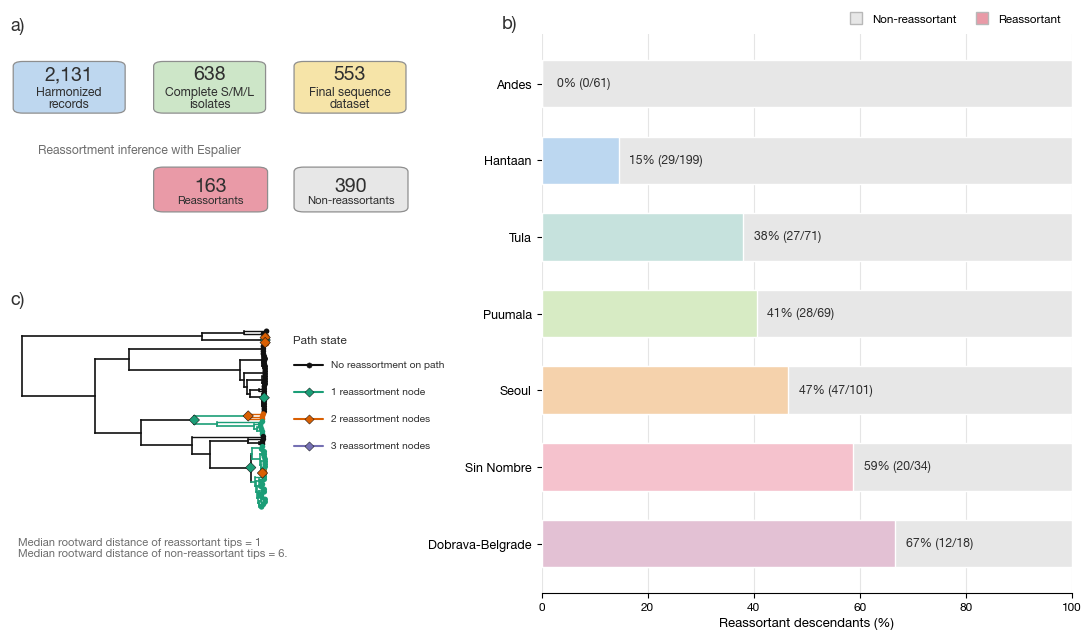

Saved notebooks/figures/figure1_descriptive.jpeg
Saved notebooks/figures/figure1_descriptive.svg
Saved notebooks/figures/figure1_descriptive.pdf
Tula reassortment nodes shown on S tree: 8


In [6]:
fig = plt.figure(figsize=(13.7, 7.25), facecolor="white")
grid = fig.add_gridspec(
    2,
    2,
    width_ratios=[1.12, 1.48],
    height_ratios=[0.82, 1.18],
    wspace=0.28,
    hspace=0.34,
)
ax_a = fig.add_subplot(grid[0, 0])
ax_b = fig.add_subplot(grid[:, 1])
ax_c = fig.add_subplot(grid[1, 0])

add_flow_panel(ax_a)
add_species_rate_panel(ax_b)
tula_reassortment_nodes_shown = add_tula_tree_panel(ax_c)

jpeg_path = OUT_DIR / "figure1_descriptive.jpeg"
svg_path = OUT_DIR / "figure1_descriptive.svg"
pdf_path = OUT_DIR / "figure1_descriptive.pdf"
fig.savefig(jpeg_path, dpi=600, bbox_inches="tight")
fig.savefig(svg_path, dpi=600, bbox_inches="tight")
fig.savefig(pdf_path, dpi=600, bbox_inches="tight")
plt.show()

print(f"Saved {jpeg_path.relative_to(REPO_ROOT)}")
print(f"Saved {svg_path.relative_to(REPO_ROOT)}")
print(f"Saved {pdf_path.relative_to(REPO_ROOT)}")
print(f"Tula reassortment nodes shown on S tree: {tula_reassortment_nodes_shown}")
